# Smart Tourist Routing and Risk Alert System
## Random Forest — Final Improved Training & Evaluation
Reproduces `improve_weather_model.py` (2023 training for threshold tuning, 2024 validation, 2023–24 final training, 2025 test). **Predicts next-day rainfall ≥20 mm, not floods, landslides, or roadblocks.**

In [1]:
!pip -q install pandas numpy scikit-learn matplotlib joblib

### 1. Load uploaded historical weather CSV
Upload `historical_weather.csv` using the Colab Files sidebar → Upload to session storage before running this cell.

In [2]:
from pathlib import Path
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_recall_fscore_support, confusion_matrix, accuracy_score, average_precision_score, precision_recall_curve, roc_curve, roc_auc_score, ConfusionMatrixDisplay)

SOURCE = Path("/content/historical_weather.csv")
OUT = Path("/content/model_outputs")
OUT.mkdir(parents=True, exist_ok=True)
THRESHOLD_MM = 20.0
if not SOURCE.exists():
    raise FileNotFoundError("Upload historical_weather.csv to Colab session storage first")
df = pd.read_csv(SOURCE, parse_dates=["date"])
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5480, 9)


,location,latitude,longitude,date,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,wind_speed_10m_max
0,Kandy,7.2906,80.6337,2023-01-01,26.2,17.7,0.0,0.0,15.0
1,Kandy,7.2906,80.6337,2023-01-02,25.9,18.9,0.0,0.0,21.8
2,Kandy,7.2906,80.6337,2023-01-03,26.2,18.2,0.4,0.4,17.7
3,Kandy,7.2906,80.6337,2023-01-04,27.0,18.5,0.0,0.0,18.1
4,Kandy,7.2906,80.6337,2023-01-05,26.6,20.5,0.7,0.7,18.7


### 2. Prepare features and next-day labels
Only current-day weather observations are used as inputs. The label is whether the **following day** recorded at least 20 mm precipitation.

In [3]:
weather = ['temperature_2m_max', 'temperature_2m_min', 'precipitation_sum',
           'rain_sum', 'wind_speed_10m_max']
required = ['location', 'latitude', 'longitude', 'date', *weather]
if any(c not in df.columns for c in required):
    raise ValueError(f'Missing required columns: {set(required)-set(df.columns)}')
if df.duplicated(['location', 'date']).any():
    raise ValueError('Duplicate location/date rows found')
df = df.sort_values(['location', 'date']).copy()
for col in ['latitude', 'longitude', *weather]:
    df[col] = pd.to_numeric(df[col], errors='coerce')
g = df.groupby('location', sort=False)
df['next_day_precipitation_mm'] = g['precipitation_sum'].shift(-1)
df['next_date'] = g['date'].shift(-1)
df = df[(df['next_date']-df['date']).dt.days == 1].copy()
df['target'] = (df['next_day_precipitation_mm'] >= THRESHOLD_MM).astype(int)
df['month_sin'] = np.sin(2*np.pi*df['date'].dt.month/12)
df['month_cos'] = np.cos(2*np.pi*df['date'].dt.month/12)
df['day_of_year_sin'] = np.sin(2*np.pi*df['date'].dt.dayofyear/365.25)
df['day_of_year_cos'] = np.cos(2*np.pi*df['date'].dt.dayofyear/365.25)
features = ['latitude', 'longitude', *weather, 'month_sin', 'month_cos',
            'day_of_year_sin', 'day_of_year_cos']
df = df.dropna(subset=features + ['next_day_precipitation_mm'])
print("Usable rows:",len(df), "Positive labels:",int(df["target"].sum()))
display(df[["location","date","precipitation_sum","next_day_precipitation_mm","target"]].head())

Usable rows: 5475 Positive labels: 428


,location,date,precipitation_sum,next_day_precipitation_mm,target
4384,Colombo,2023-01-01,0.0,0.0,0
4385,Colombo,2023-01-02,0.0,0.1,0
4386,Colombo,2023-01-03,0.1,0.0,0
4387,Colombo,2023-01-04,0.0,1.2,0
4388,Colombo,2023-01-05,1.2,8.2,0


### 3. Split chronologically and select threshold on validation only

In [4]:
train = df[df['date'].dt.year == 2023]
valid = df[df['date'].dt.year == 2024]
test = df[df['date'].dt.year == 2025]
if any(x.empty for x in (train, valid, test)):
    raise ValueError('Need 2023 train, 2024 validation and 2025 test data')
if train['target'].nunique() != 2 or valid['target'].nunique() != 2:
    raise ValueError('Training and validation must contain both classes')

params = dict(n_estimators=250, max_depth=12, min_samples_leaf=5,
              class_weight='balanced_subsample', random_state=42, n_jobs=-1)
validation_model = RandomForestClassifier(**params)
validation_model.fit(train[features], train['target'])
valid_prob = validation_model.predict_proba(valid[features])[:, 1]

# Choose a threshold by validation F2 (recall emphasized), NOT test performance.
thresholds = np.round(np.arange(0.10, 0.81, 0.05), 2)
records = []
for t in thresholds:
    predictions = (valid_prob >= t).astype(int)
    p, r, f2, _ = precision_recall_fscore_support(
        valid['target'], predictions, average='binary', beta=2, zero_division=0)
    records.append({'threshold': float(t), 'precision': float(p),
                    'recall': float(r), 'f2': float(f2)})
validation_results = pd.DataFrame(records)
validation_results.to_csv(OUT / 'threshold_validation.csv', index=False)
chosen = sorted(records, key=lambda x: (-x['f2'], -x['precision'], x['threshold']))[0]['threshold']

print("Train:",len(train),"Validation:",len(valid),"Test:",len(test))
print("Selected threshold:",chosen)
display(validation_results)

Train: 1825 Validation: 1830 Test: 1820
Selected threshold: 0.15


,threshold,precision,recall,f2
0,0.10,0.145754,0.851852,0.432656
1,0.15,0.156609,0.807407,0.440939
2,0.20,0.159677,0.733333,0.426724
3,0.25,0.175926,0.703704,0.439815
4,0.30,0.190476,0.651852,0.439122
5,0.35,0.195531,0.518519,0.389755
6,0.40,0.204225,0.429630,0.351942
7,0.45,0.193694,0.318519,0.282152
8,0.50,0.203593,0.251852,0.240453
9,0.55,0.217054,0.207407,0.209268


### 4. Retrain on 2023–24 and evaluate on held-out 2025

In [5]:
# Final training uses 2023+2024, then 2025 is tested exactly once.
final_train = df[df['date'] < '2025-01-01']
final_model = RandomForestClassifier(**params)
final_model.fit(final_train[features], final_train['target'])
test_prob = final_model.predict_proba(test[features])[:, 1]

def score(pred):
    p, r, f1, _ = precision_recall_fscore_support(
        test['target'], pred, average='binary', zero_division=0)
    _, _, f2, _ = precision_recall_fscore_support(
        test['target'], pred, average='binary', beta=2, zero_division=0)
    return {'accuracy': round(float(accuracy_score(test['target'], pred)), 4),
            'precision': round(float(p), 4), 'recall': round(float(r), 4),
            'f1': round(float(f1), 4), 'f2': round(float(f2), 4),
            'confusion_matrix': confusion_matrix(test['target'], pred, labels=[0, 1]).tolist()}

original = (test_prob >= 0.50).astype(int)
improved = (test_prob >= chosen).astype(int)
results = {
    'task': 'Next-day rainfall >= 20mm; NOT verified flood/landslide prediction',
    'data_split': '2023 threshold-model training; 2024 threshold validation; 2023-24 final model training; 2025 held-out testing',
    'selected_probability_threshold': chosen,
    'validation_selection_metric': 'F2 (emphasizes recall)',
    'test_rows': len(test), 'test_heavy_rain_days': int(test['target'].sum()),
    'test_average_precision': round(float(average_precision_score(test['target'], test_prob)), 4),
    'threshold_0_50': score(original), 'selected_threshold': score(improved),
    'warning': 'Weather screening only; not an official hazard alert. Same-day observed features cannot be used before they are available.'
}
print("0.50 threshold:",results["threshold_0_50"])
print("Selected threshold:",results["selected_threshold"])
print("2025 average precision:",results["test_average_precision"])

0.50 threshold: {'accuracy': 0.894, 'precision': 0.302, 'recall': 0.3358, 'f1': 0.318, 'f2': 0.3285, 'confusion_matrix': [[1582, 104], [89, 45]]}
Selected threshold: {'accuracy': 0.6808, 'precision': 0.1649, 'recall': 0.8209, 'f1': 0.2747, 'f2': 0.4572, 'confusion_matrix': [[1129, 557], [24, 110]]}
2025 average precision: 0.3514


### 5. Visualizations — actual test results

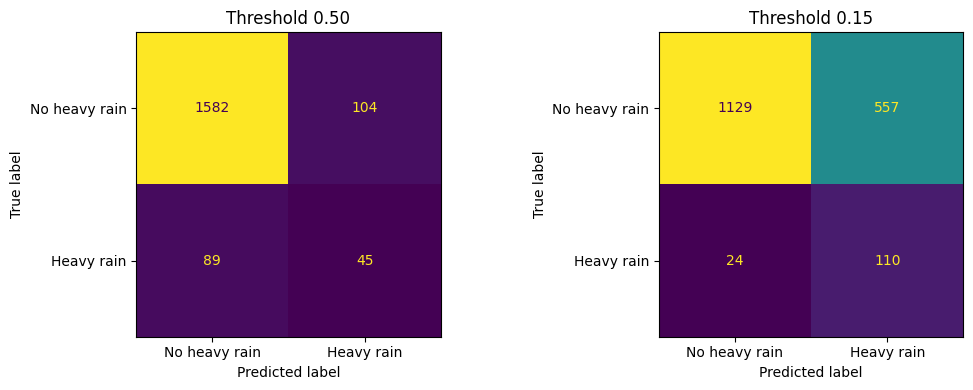

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(test["target"], original, labels=[0,1]), display_labels=["No heavy rain","Heavy rain"]).plot(ax=axes[0],colorbar=False)
axes[0].set_title("Threshold 0.50")
ConfusionMatrixDisplay(confusion_matrix(test["target"], improved, labels=[0,1]), display_labels=["No heavy rain","Heavy rain"]).plot(ax=axes[1],colorbar=False)
axes[1].set_title(f"Threshold {chosen:.2f}")
plt.tight_layout(); plt.show()

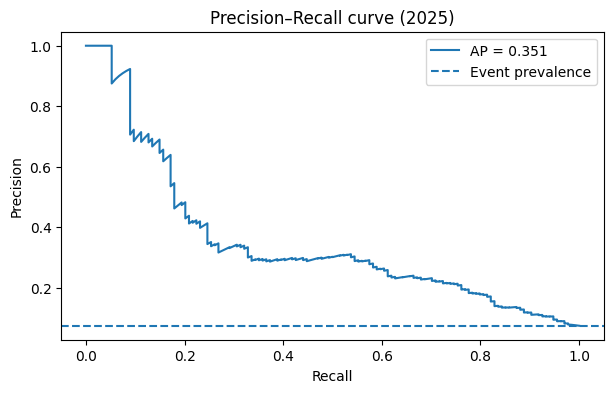

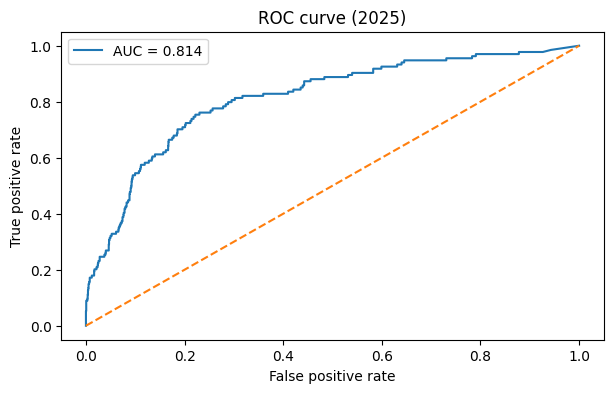

In [7]:
precision, recall, _ = precision_recall_curve(test["target"], test_prob)
fpr, tpr, _ = roc_curve(test["target"], test_prob)
plt.figure(figsize=(7,4)); plt.plot(recall,precision,label=f"AP = {average_precision_score(test['target'],test_prob):.3f}"); plt.axhline(test["target"].mean(),linestyle="--",label="Event prevalence"); plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision–Recall curve (2025)"); plt.legend(); plt.show()
plt.figure(figsize=(7,4)); plt.plot(fpr,tpr,label=f"AUC = {roc_auc_score(test['target'],test_prob):.3f}"); plt.plot([0,1],[0,1],linestyle="--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curve (2025)"); plt.legend(); plt.show()

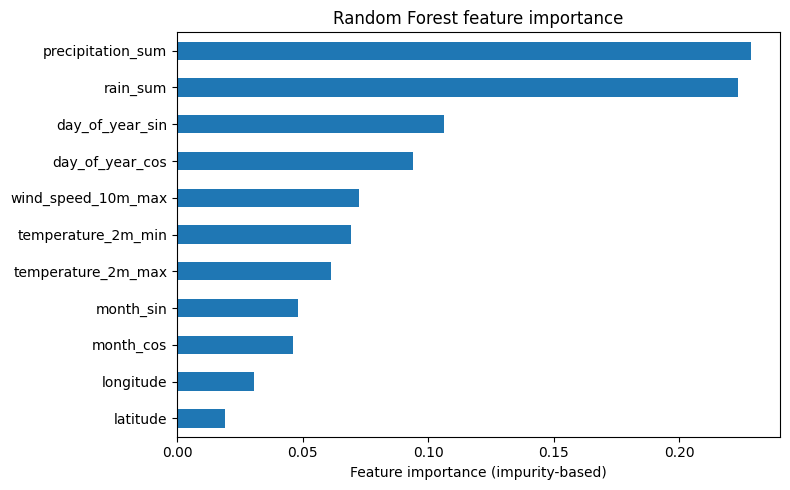

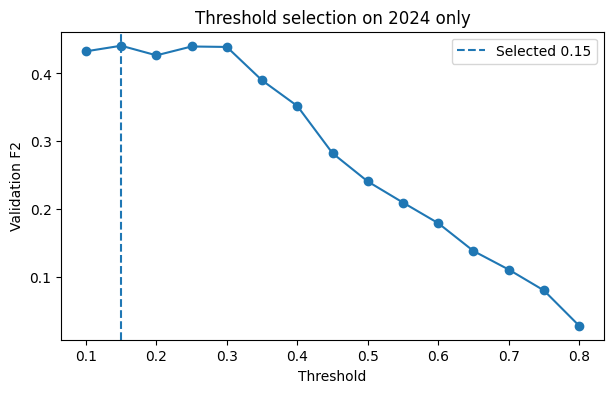

In [8]:
importance = pd.Series(final_model.feature_importances_, index=features).sort_values()
plt.figure(figsize=(8,5)); importance.plot.barh(); plt.xlabel("Feature importance (impurity-based)"); plt.title("Random Forest feature importance"); plt.tight_layout(); plt.show()
plt.figure(figsize=(7,4)); plt.plot(validation_results["threshold"],validation_results["f2"],marker="o"); plt.axvline(chosen,linestyle="--",label=f"Selected {chosen:.2f}"); plt.xlabel("Threshold"); plt.ylabel("Validation F2"); plt.title("Threshold selection on 2024 only"); plt.legend(); plt.show()

### 6. Save reproducible model and evaluation files
The exported `weather_risk_model_v2.joblib` has the same schema as the VS Code training script. Compare its metrics with the VS Code run before handing over.

In [9]:
joblib.dump({'model': final_model, 'features': features, 'threshold_mm': THRESHOLD_MM,
             'probability_threshold': chosen, 'task': results['task']},
            OUT / 'weather_risk_model_v2.joblib')
(OUT / 'improved_evaluation_metrics.json').write_text(json.dumps(results, indent=2), encoding='utf-8')
test[['location', 'date', 'next_day_precipitation_mm', 'target']].assign(
    predicted_probability=test_prob, prediction_at_050=original,
    prediction_at_selected_threshold=improved).to_csv(OUT / 'improved_test_predictions.csv', index=False)
print('IMPROVED MODEL TRAINING COMPLETED')
print('Selected threshold (using 2024 validation only):', chosen)
print('2025 test, original threshold 0.50:', results['threshold_0_50'])
print('2025 test, selected threshold:', results['selected_threshold'])
print('2025 average precision:', results['test_average_precision'])
print('Saved files to:', OUT)

print("Output files:",[p.name for p in OUT.iterdir()])

IMPROVED MODEL TRAINING COMPLETED
Selected threshold (using 2024 validation only): 0.15
2025 test, original threshold 0.50: {'accuracy': 0.894, 'precision': 0.302, 'recall': 0.3358, 'f1': 0.318, 'f2': 0.3285, 'confusion_matrix': [[1582, 104], [89, 45]]}
2025 test, selected threshold: {'accuracy': 0.6808, 'precision': 0.1649, 'recall': 0.8209, 'f1': 0.2747, 'f2': 0.4572, 'confusion_matrix': [[1129, 557], [24, 110]]}
2025 average precision: 0.3514
Saved files to: /content/model_outputs
Output files: ['improved_test_predictions.csv', 'weather_risk_model_v2.joblib', 'threshold_validation.csv', 'improved_evaluation_metrics.json']


In [10]:

from sklearn.metrics import accuracy_score

# Predictions using the selected threshold
y_pred = (test_prob >= chosen).astype(int)

accuracy = accuracy_score(test["target"], y_pred)

print("Random Forest Accuracy:", round(accuracy * 100, 2), "%")


Random Forest Accuracy: 68.08 %


### 7. Limitations
- The 20 mm threshold is a research choice, **not** an official disaster warning threshold.
- 0.15 was selected on 2024 validation to favor recall; 2025 test precision is low and false positives are high.
- The inputs include **observed current-day weather**. Do not claim a forecast is available before those observations exist.
- Weather screening is not verified flood, landslide, or roadblock prediction.
- Reanalysis/historical weather observations are not a substitute for live hazard reporting.